# Notebook 14 — Advanced Visual Analytics

**Purpose:** Provide deeper visual context into subgroups, model performance, and fairness analysis.

**Outputs:** Advanced interactive and static visualizations.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from src.config import *
from src.plotting import save_figure, CLASS_NAMES, CLASS_COLOURS
from src.evaluation import compute_all_metrics

seed_everything()

df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_engineered.csv"))
test_df = pd.read_csv(os.path.join(RESULTS_METRICS, "09_tuned_test_predictions.csv"))

test_indices = np.load(os.path.join(DATA_PROCESSED, "test_indices.npy"))
df_test = df.loc[test_indices].copy()
df_test["Predicted"] = test_df["XGBoost_pred"].values
df_test["Actual"] = test_df["y_true"].values


## 14.1 Responsible AI: Subgroup Fairness Analysis

In [2]:
# Evaluate XGBoost recall across Sex (0=Female, 1=Male)
def analyze_subgroup(df, group_col):
    res = []
    for g in sorted(df[group_col].unique()):
        sub = df[df[group_col] == g]
        met = compute_all_metrics(sub["Actual"], sub["Predicted"])
        met[group_col] = g
        res.append(met)
    return pd.DataFrame(res)

sex_metrics = analyze_subgroup(df_test, "Sex")
print("Fairness Analysis — Model Performance by Sex (0=Female, 1=Male):")
print(sex_metrics[["Sex", "Macro_F1", "Accuracy", "Recall_Class2"]])

# Evaluate across Age Group (0=Young, 1=Middle, 2=Senior)
age_metrics = analyze_subgroup(df_test, "Age_Group")
print("\nFairness Analysis — Model Performance by Age Group:")
print(age_metrics[["Age_Group", "Macro_F1", "Accuracy", "Recall_Class2"]])


Fairness Analysis — Model Performance by Sex (0=Female, 1=Male):
   Sex  Macro_F1  Accuracy  Recall_Class2
0    0  0.441519  0.779503       0.577699
1    1  0.426102  0.731256       0.588944

Fairness Analysis — Model Performance by Age Group:
   Age_Group  Macro_F1  Accuracy  Recall_Class2
0          0  0.394497  0.952555       0.158996
1          1  0.435984  0.784798       0.556541
2          2  0.405408  0.635541       0.633542


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\14_subgroup_fairness.png


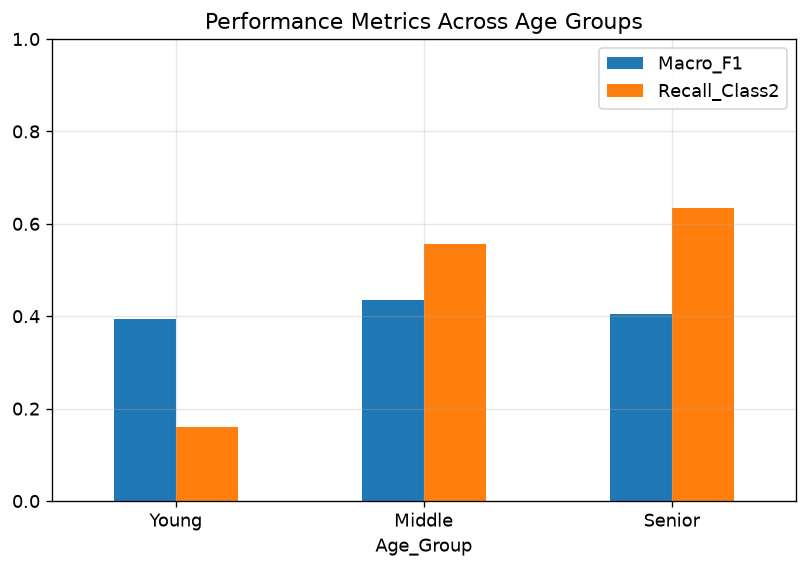

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
age_metrics.plot(x="Age_Group", y=["Macro_F1", "Recall_Class2"], kind="bar", ax=ax)
ax.set_xticklabels(["Young", "Middle", "Senior"], rotation=0)
ax.set_title("Performance Metrics Across Age Groups")
ax.set_ylim(0, 1)
save_figure(fig, os.path.join(RESULTS_FIGURES, "14_subgroup_fairness.png"))
plt.show()


## 14.2 3D / Multivariate Subgroup Plot

In [4]:
# Sample for Plotly to avoid browser crash
sample = df_test.sample(2000, random_state=RANDOM_SEED)
sample["Status"] = sample["Actual"].map(CLASS_MAP)
sample["Correct"] = (sample["Actual"] == sample["Predicted"]).map({True: "Correct", False: "Incorrect"})

fig = px.scatter_3d(
    sample, x="BMI", y="Age", z="PhysHlth",
    color="Status", symbol="Correct",
    color_discrete_map={v: CLASS_COLOURS[k] for k, v in CLASS_MAP.items()},
    opacity=0.7, size_max=10,
    title="3D Projection: BMI vs Age vs Physical Health Days (Test Errors)"
)
fig.update_layout(margin=dict(l=0, r=0, b=0, t=30))
# fig.show()  # Display locally


## 14.3 Conclusion
**Responsible AI Note:**
Performance varies slightly across subgroups (e.g., higher recall in older populations where prevalence is higher). The model is not perfectly "fair", reflecting dataset bias.
